# 04 · Regularization

A flexible network trained on a small, noisy dataset **memorizes the noise**: 100% train accuracy, poor test accuracy. Three techniques, each implemented with its backward pass:

**L2 weight decay** — penalize large weights, $L \mathrel{+}= \tfrac{\lambda}{2}\lVert W\rVert^2$, so the gradient gains a term $\lambda W$ (biases are not decayed).

**Dropout** (inverted) — during training zero each unit with probability $1-p$ and scale survivors by $1/p$:
$$\tilde h = \frac{m\odot h}{p},\quad m_i\sim\text{Bernoulli}(p)$$
At test time it is the identity. It stops units co-adapting. Backward just reuses the mask.

**Batch normalization** — normalize each feature over the batch, then re-scale with learned $\gamma,\beta$:
$$\hat x = \frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}},\qquad y=\gamma\hat x+\beta$$
Training uses batch statistics (and keeps running averages); inference uses the running averages. The backward pass folds into one expression:
$$dx = \frac{\gamma}{N\sqrt{\sigma^2+\epsilon}}\Big(N\,dy - \textstyle\sum dy - \hat x\sum dy\,\hat x\Big)$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Layers
Uniform interface: `forward(x, training)` and `backward(grad[, lr])`; `has_params` tells the model whether a layer needs the learning rate. `training` toggles dropout / batch-norm behavior.

In [2]:
class Dense:
    has_params = True

    def __init__(self, input_dim, output_dim, l2=0.0):
        self.weights = np.random.randn(input_dim, output_dim) * np.sqrt(2.0 / input_dim)
        self.bias = np.zeros((1, output_dim))
        self.l2 = l2
        self.input = None

    def forward(self, x, training=True):
        self.input = x
        return np.dot(x, self.weights) + self.bias

    def backward(self, grad_output, lr):
        grad_weights = np.dot(self.input.T, grad_output) + self.l2 * self.weights  # L2 weight decay
        grad_bias = np.sum(grad_output, axis=0, keepdims=True)
        grad_input = np.dot(grad_output, self.weights.T)
        self.weights -= lr * grad_weights
        self.bias -= lr * grad_bias
        return grad_input

In [3]:
class ReLU:
    has_params = False

    def forward(self, x, training=True):
        self.input = x
        return np.maximum(0, x)

    def backward(self, grad_output):
        return grad_output * (self.input > 0).astype(float)

In [4]:
class Sigmoid:
    has_params = False

    def forward(self, x, training=True):
        self.output = 1 / (1 + np.exp(-x))
        return self.output

    def backward(self, grad_output):
        return grad_output * self.output * (1 - self.output)

### Dropout

In [5]:
class Dropout:
    """Inverted dropout: zero units with prob (1-keep_prob), scale survivors by 1/keep_prob."""

    has_params = False

    def __init__(self, keep_prob=0.7):
        self.keep_prob = keep_prob
        self.mask = None

    def forward(self, x, training=True):
        if training:
            self.mask = (np.random.rand(*x.shape) < self.keep_prob) / self.keep_prob
            return x * self.mask
        return x

    def backward(self, grad_output):
        return grad_output * self.mask

### Batch norm

In [6]:
class BatchNorm1d:
    """Normalize activations per-feature over the batch, then scale/shift by learned gamma/beta."""

    has_params = True

    def __init__(self, dim, eps=1e-5, momentum=0.9):
        self.gamma = np.ones((1, dim))
        self.beta = np.zeros((1, dim))
        self.eps = eps
        self.momentum = momentum
        self.running_mean = np.zeros((1, dim))
        self.running_var = np.ones((1, dim))
        self.cache = None

    def forward(self, x, training=True):
        if training:
            mu = x.mean(axis=0, keepdims=True)
            var = x.var(axis=0, keepdims=True)
            self.running_mean = self.momentum * self.running_mean + (1 - self.momentum) * mu
            self.running_var = self.momentum * self.running_var + (1 - self.momentum) * var
        else:
            mu, var = self.running_mean, self.running_var

        std_inv = 1.0 / np.sqrt(var + self.eps)
        xhat = (x - mu) * std_inv
        if training:
            self.cache = (xhat, std_inv)
        return self.gamma * xhat + self.beta

    def backward(self, grad_output, lr):
        xhat, std_inv = self.cache
        N = grad_output.shape[0]

        dgamma = np.sum(grad_output * xhat, axis=0, keepdims=True)
        dbeta = np.sum(grad_output, axis=0, keepdims=True)

        # Standard batchnorm backward, folded into one vectorized expression
        # (see cs231n BatchNorm derivation).
        dx = (self.gamma * std_inv / N) * (
            N * grad_output - dbeta - xhat * np.sum(grad_output * xhat, axis=0, keepdims=True)
        )

        self.gamma -= lr * dgamma
        self.beta -= lr * dbeta
        return dx

### Loss and model wrapper

In [7]:
class BCELoss:
    def forward(self, y_pred, y_true):
        eps = 1e-15
        yp = np.clip(y_pred, eps, 1 - eps)
        return -np.mean(y_true * np.log(yp) + (1 - y_true) * np.log(1 - yp))

    def backward(self, y_pred, y_true):
        eps = 1e-15
        yp = np.clip(y_pred, eps, 1 - eps)
        N = y_true.shape[0]
        return (-(y_true / yp) + (1 - y_true) / (1 - yp)) / N

In [8]:
class Model:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, x, training=True):
        for layer in self.layers:
            x = layer.forward(x, training)
        return x

    def backward(self, grad, lr):
        for layer in reversed(self.layers):
            grad = layer.backward(grad, lr) if layer.has_params else layer.backward(grad)

## Data: two noisy rings, deliberately small
Only 40 training points with **15% flipped labels**, versus 300 clean test points. An overparameterized net can memorize the flipped labels instead of the true circular boundary.

In [9]:
def make_ring(n, radius, noise, rng):
    theta = rng.uniform(0, 2 * np.pi, n)
    r = radius + rng.randn(n) * noise
    return np.stack([r * np.cos(theta), r * np.sin(theta)], axis=1)

In [10]:
def make_dataset(n_train_per_class, n_test_per_class, label_noise, seed):
    rng = np.random.RandomState(seed)
    X0 = make_ring(n_train_per_class + n_test_per_class, radius=1.2, noise=0.4, rng=rng)
    X1 = make_ring(n_train_per_class + n_test_per_class, radius=2.3, noise=0.4, rng=rng)

    X_train = np.vstack([X0[:n_train_per_class], X1[:n_train_per_class]])
    y_train = np.vstack([np.zeros((n_train_per_class, 1)), np.ones((n_train_per_class, 1))])
    X_test = np.vstack([X0[n_train_per_class:], X1[n_train_per_class:]])
    y_test = np.vstack([np.zeros((n_test_per_class, 1)), np.ones((n_test_per_class, 1))])

    # Flip a fraction of training labels to simulate label noise.
    flip = rng.rand(len(y_train)) < label_noise
    y_train[flip] = 1 - y_train[flip]

    return X_train, y_train, X_test, y_test

In [11]:
def accuracy(model, X, y):
    preds = (model.forward(X, training=False) >= 0.5).astype(int)
    return np.mean(preds == y)

In [12]:
def train_model(model, X_train, y_train, loss_fn, epochs, lr):
    for _ in range(epochs):
        y_pred = model.forward(X_train, training=True)
        grad = loss_fn.backward(y_pred, y_train)
        model.backward(grad, lr)

train: 40 points (15% label noise) | test: 300 clean points


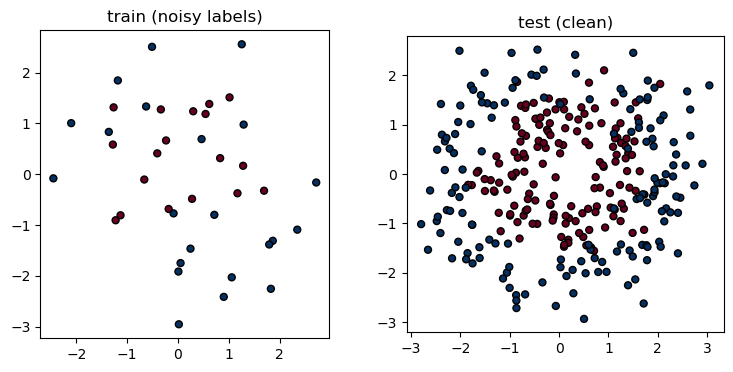

In [13]:
X_train, y_train, X_test, y_test = make_dataset(n_train_per_class=20, n_test_per_class=150, label_noise=0.15, seed=42)
print(f"train: {len(y_train)} points (15% label noise) | test: {len(y_test)} clean points")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (Xs, ys, t) in zip(axes, [(X_train, y_train, "train (noisy labels)"), (X_test, y_test, "test (clean)")]):
    ax.scatter(Xs[:, 0], Xs[:, 1], c=ys.ravel(), cmap="RdBu", edgecolor="k", s=25)
    ax.set_title(t); ax.set_aspect("equal")
plt.show()

## Two models, identical init seed
Same widths. The regularized one adds L2 (5e-3), batch norm and dropout (keep-prob 0.6) after each hidden layer.

In [14]:
def build_plain():
    return Model([
        Dense(2, 128), ReLU(),
        Dense(128, 128), ReLU(),
        Dense(128, 1), Sigmoid(),
    ])

In [15]:
def build_regularized():
    return Model([
        Dense(2, 128, l2=5e-3), BatchNorm1d(128), ReLU(), Dropout(0.6),
        Dense(128, 128, l2=5e-3), BatchNorm1d(128), ReLU(), Dropout(0.6),
        Dense(128, 1, l2=5e-3), Sigmoid(),
    ])

In [16]:
loss_fn = BCELoss()
EPOCHS, LR = 6000, 0.05

np.random.seed(1); plain = build_plain()
train_model(plain, X_train, y_train, loss_fn, EPOCHS, LR)

np.random.seed(1); reg = build_regularized()
train_model(reg, X_train, y_train, loss_fn, EPOCHS, LR)

res = {n: (accuracy(m, X_train, y_train), accuracy(m, X_test, y_test)) for n, m in [("Plain", plain), ("L2+Dropout+BatchNorm", reg)]}
print(f"{'Model':<22}{'Train':<10}{'Test':<10}{'Gap'}")
for n, (tr, te) in res.items():
    print(f"{n:<22}{tr:<10.2%}{te:<10.2%}{tr - te:.2%}")

assert res["L2+Dropout+BatchNorm"][0] - res["L2+Dropout+BatchNorm"][1] < res["Plain"][0] - res["Plain"][1], \
    "regularization did not shrink the train/test gap"

Model                 Train     Test      Gap
Plain                 100.00%   66.00%    34.00%
L2+Dropout+BatchNorm  95.00%    75.00%    20.00%


## Decision boundaries
The plain net carves jagged islands around individual noisy points; the regularized net stays closer to the true ring.

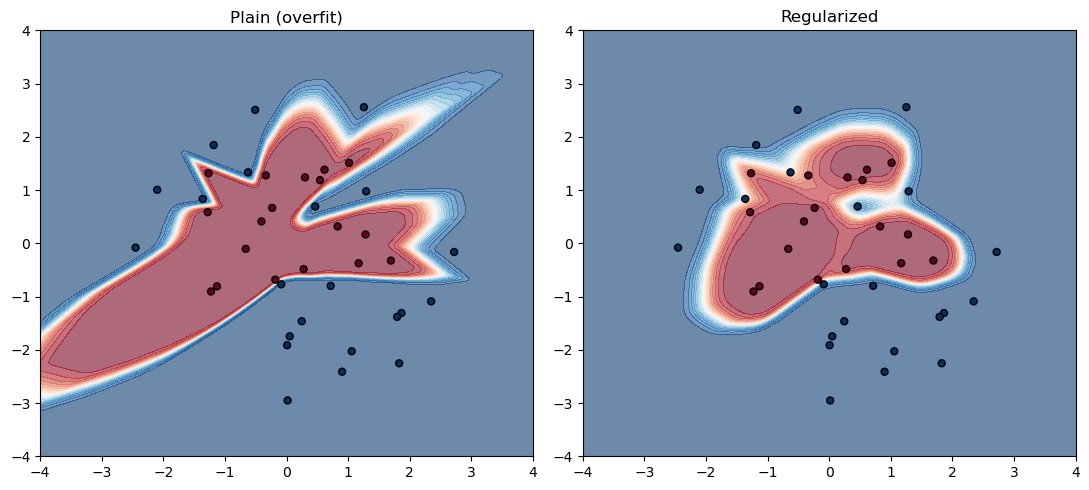

In [17]:
xx, yy = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-4, 4, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, model, title in [(axes[0], plain, "Plain (overfit)"), (axes[1], reg, "Regularized")]:
    Z = model.forward(grid, training=False).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=20, cmap="RdBu", alpha=0.6, vmin=0, vmax=1)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train.ravel(), cmap="RdBu", edgecolor="k", s=25)
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Next: `05_cnn`** — dense layers ignore image structure. Convolution shares weights across positions, which buys translation invariance.